<a href="https://colab.research.google.com/github/faiqnabil/Pembelajaran-Mesin-2026/blob/main/TG11_244107020025_M_Faiq_Nabil_Saputra_JS11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Praktikum 1**

Langkah 1 — Import Library

In [ ]:

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns


Langkah 2 — Membuat Data Dummy

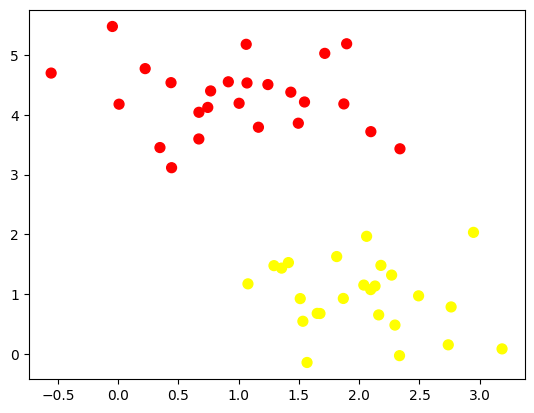

In [ ]:

from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')


Langkah 3 — Membuat Ilustrasi Garis Pemisah

(-1.0, 6.0)

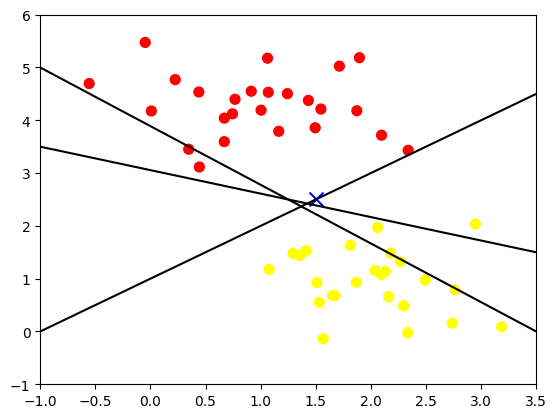

In [ ]:

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

plt.plot([-1, 3.5], [0, 4.5], '-k')
plt.plot([-1, 3.5], [3.5, 1.5], '-k')
plt.plot([-1, 3.5], [5, 0], '-k')

plt.scatter(1.5, 2.5, marker='x', color='blue', s=100)

plt.xlim(-1, 3.5)
plt.ylim(-1, 6)


Langkah 4 — Ilustrasi Margin

(-1.0, 3.5)

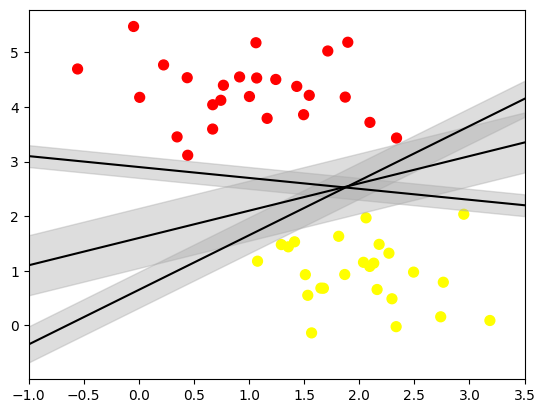

In [ ]:

xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)


Langkah 5 — Fitting Model

Melatih model SVM

In [ ]:

from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)


SVC(C=10000000000.0, kernel='linear')

Membuat fungsi visualisasi SVM

In [ ]:

# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


Menampilkan garis pemisah dan support vectors

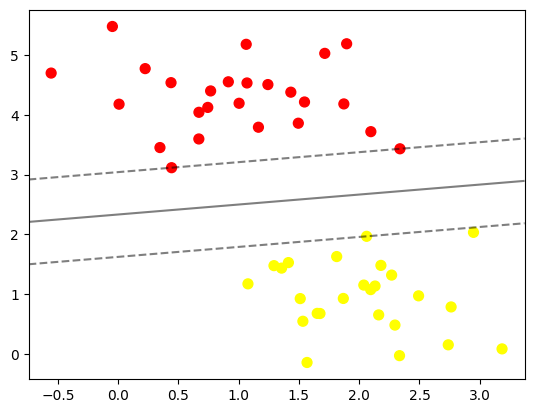

In [ ]:

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)


Menampilkan nilai support vectors

In [ ]:

model.support_vectors_


array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Membandingkan jumlah data 60 dan 120

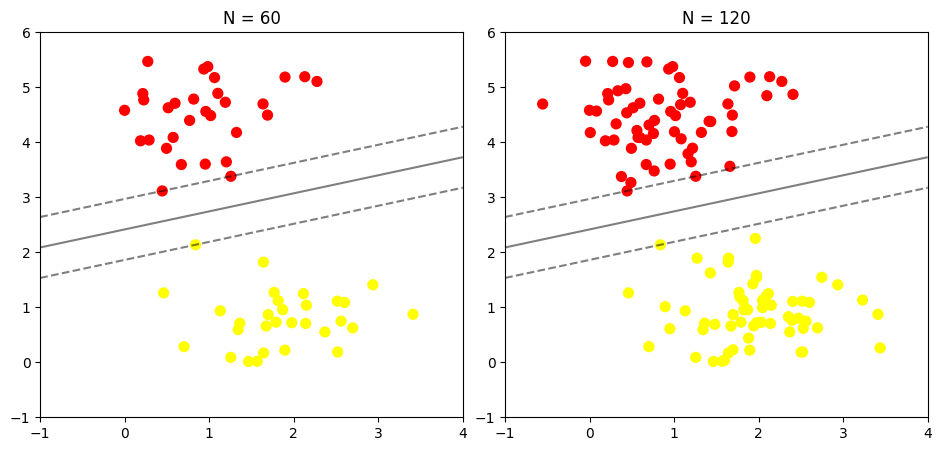

In [ ]:

def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))


Interaksi jumlah data menggunakan ipywidgets

In [ ]:

# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))


interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

## **Praktikum 2**

Langkah 1 — Ilustrasi Data Non-Linier

Langkah 1a — Import Library

In [ ]:

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC


Langkah 1b — Buat Kembali Fungsi Plotting

In [ ]:

# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


Langkah 1c — Buat Data Dummy Non-Linier

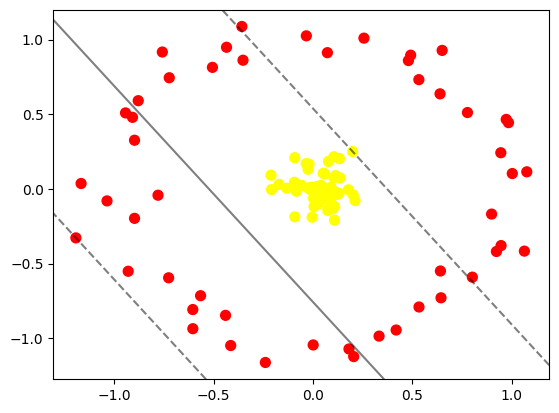

In [ ]:

# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);


Langkah 1d — Proyeksi Data ke Dimensi 3D

In [ ]:

r = np.exp(-(X**2).sum(1))


In [ ]:

from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))


interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.06383325e+00, -4.17011373e-01],
       [-7.24087995e-01,  7.44383337e-01],
       [-1.10717021e-02,  1.01030548e-02],
       [ 7.20386539e-02,  9.12423068e-01],
       [-3.46225798e-02,  1.69028456e-01],
       [ 7.67541316e-02,  5.98254242e-03],
       [ 1.00297435e+00,  1.02762961e-01],
       [-3.52815214e-01,  8.61910775e-01],
       [-4.40761689e-01, -8.47218263e-01],
       [ 8.82270766e-02, -8.36893671e-02],
       [ 9.46545918e-01, -3.79868608e-01],
       [-2.11904100e-01,  9.16856585e-02],
       [ 3.32216309e-01, -9.86406011e-01],
       [-8.46490679e-02, -1.56812369e-02],
       [ 1.07604597e+00,  1.14221980e-01],
       [ 7.40271722e-02, -1.43788193e-01],
       [ 1.32395052e-01,  2.02257399e-01],
       [ 1.99265170e-01,  2.49779636e-01],
       [ 1.04144196e-01,  7.48705528e-02],
       [-2.05730486e-02,  1.65475940e-01],
       [ 4.70603355e-03, -1.18201900e-01],
       [-5.06723274e-01,  8.14004081e-01],
       [-2.54781974e-02,  6.18353455e-03],
       [-7.58964241e-01,  9.16738984e-01],
       [-5.66433958e-01, -7.15620962e-01],
       [ 2.56063556e-01,  1.00969672e+00],
       [ 4.80004792e-01,  8.59631654e-01],
       [ 6.49907896e-01,  9.27600992e-01],
       [-9.09060253e-01,  4.79299646e-01],
       [ 1.08425869e-01, -1.18160779e-01],
       [-2.52840884e-02,  1.31455003e-01],
       [ 1.80791555e-01, -1.07257876e+00],
       [-8.98887517e-01,  3.25820521e-01],
       [ 7.73620945e-02,  1.83776531e-01],
       [ 1.30457738e-01, -2.97514950e-02],
       [ 8.98803037e-01, -1.68901197e-01],
       [ 3.17129604e-02, -9.79571252e-02],
       [-1.71367312e-01,  3.03794114e-02],
       [ 1.04907089e-01,  2.15254017e-01],
       [ 6.39208938e-01,  6.36673325e-01],
       [ 4.18293215e-01, -9.45577415e-01],
       [-7.80666668e-01, -4.24881802e-02],
       [-9.30863506e-01, -5.51911935e-01],
       [ 9.74847508e-02, -1.34586293e-01],
       [ 3.91973141e-02,  2.46026437e-02],
       [ 1.30976677e-01,  2.03514418e-01],
       [ 6.41219022e-01, -5.50127442e-01],
       [-6.05413002e-01, -9.36752573e-01],
       [ 7.77242634e-01,  5.11395099e-01],
       [ 1.12676962e-01,  8.87497124e-02],
       [-7.81747834e-02,  1.42056348e-02],
       [-9.44237544e-01,  5.08836625e-01],
       [ 5.79902157e-02,  1.00951475e-01],
       [ 9.45241788e-01,  2.42029701e-01],
       [-5.86489223e-02,  2.37410857e-02],
       [ 5.32637729e-01,  7.31706431e-01],
       [ 1.35661254e-01,  7.44722855e-02],
       [-3.58631184e-01,  1.08788152e+00],
       [-3.39873806e-02,  1.02524310e+00],
       [ 1.11092877e-01, -1.99754041e-02],
       [-9.17406560e-02, -1.87381385e-01],
       [ 2.04560571e-01, -1.12351029e+00],
       [-7.27224778e-01, -5.95682038e-01],
       [ 9.07647195e-02,  9.34325409e-03],
       [-1.43138065e-02, -4.01705270e-03],
       [-8.80232698e-01,  5.90793565e-01],
       [-4.83941708e-03, -1.89855115e-01],
       [-6.05573995e-01, -8.08353846e-01],
       [ 6.44114437e-01, -7.29733568e-01],
       [-2.40236661e-01, -1.16297078e+00],
       [-1.32892797e-01,  4.25439497e-03],
       [ 8.01857479e-01, -5.91456911e-01],
       [ 8.28936078e-02, -3.62046989e-02],
       [-4.14668408e-01, -1.04944358e+00],
       [ 1.95600633e-02,  1.51679289e-02],
       [ 1.78121541e-01, -6.11227038e-03],
       [-1.03750207e+00, -8.05908117e-02],
       [ 3.80879578e-02, -5.74342527e-02],
       [-9.39584406e-02,  4.42543436e-02],
       [ 9.23064227e-01, -4.19532726e-01],
       [-1.16798916e+00,  3.60455184e-02],
       [ 2.11606312e-01, -7.85854891e-02],
       [ 2.01634033e-01, -4.00749818e-02],
       [ 1.07813625e-01, -2.09688488e-01],
       [-2.09173523e-01, -5.01812660e-03],
       [-4.35675994e-01,  9.48674684e-01],
       [-9.21799172e-02,  2.09038454e-01],
       [ 1.20049374e-01, -3.75589364e-02],
       [-8.98963205e-01, -1.97409519e-01],
       [ 1.99683661e-02, -3.38986625e-02],
       [ 2.35999567e-03, -6.26850236e-02],
       [ 3.50457941e-02, -7.26152010e-02

Langkah 2 — Fitting Model dengan Kernel RBF

Melatih model

In [ ]:

clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)


SVC(C=1000000.0)

Menampilkan batas keputusan RBF

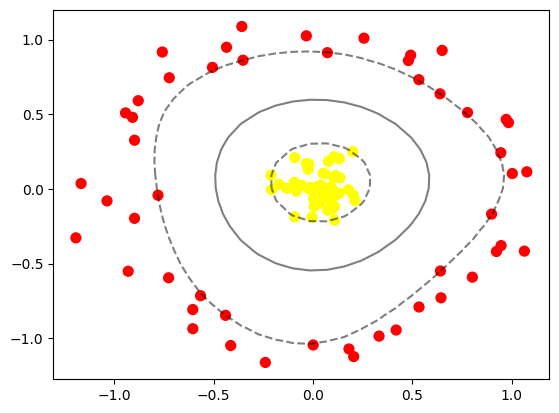

In [ ]:

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')


## **Praktikum 3**

Langkah 1 — Import Library dan Buat Fungsi Plotting

1.1. Import library

In [ ]:

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs


1.2. Membuat fungsi plotting

In [ ]:

# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


Langkah 2 — Buat Data Dummy

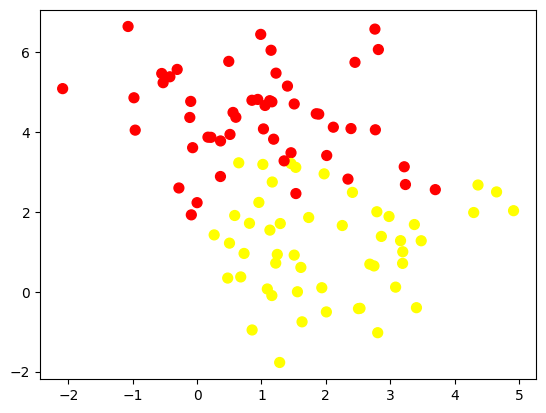

In [ ]:

X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')


Langkah 3 — Analisis Dampak Tuning

3.1. Masukkan kode program

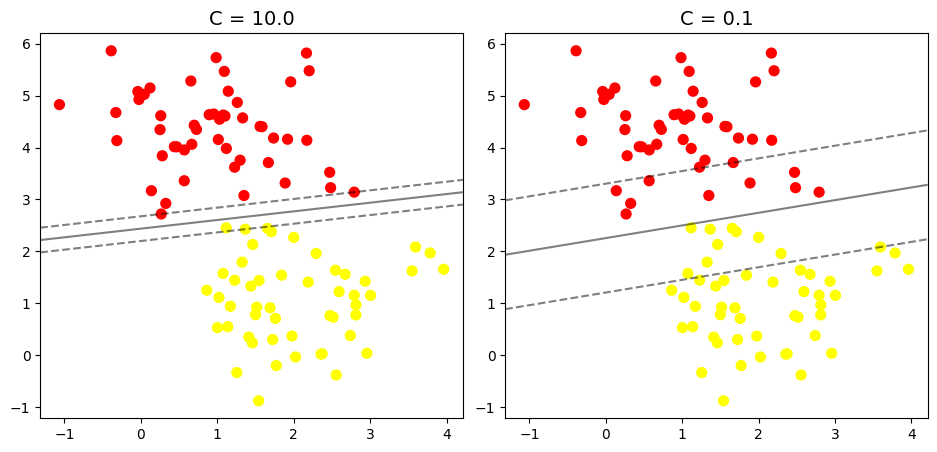

In [ ]:

X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)


3.2. Memahami hasil grafik

**Grafik kiri — C = 10.0**

Nilai \(C\) yang lebih besar memberikan penalti lebih besar terhadap kesalahan klasifikasi pada data pelatihan. Model cenderung berusaha mengklasifikasikan data pelatihan dengan lebih ketat, sehingga margin dapat menjadi lebih sempit.


**Grafik kanan — C = 0.1**

Nilai \(C\) yang lebih kecil memberikan toleransi lebih besar terhadap kesalahan klasifikasi. Model cenderung mengutamakan margin yang lebih lebar, meskipun beberapa titik mungkin berada di dalam margin atau salah diklasifikasikan.

3.3. Memahami parameter C

**C besar:**

penalti kesalahan lebih tinggi; model cenderung menyesuaikan diri lebih ketat terhadap data pelatihan.



**C kecil:**

penalti kesalahan lebih rendah; model memberi toleransi lebih besar terhadap pelanggaran margin.

## **Praktikum 4**

Langkah 0 — Unduh Dataset

In [ ]:

from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)


['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 1 — Inspeksi Citra Wajah

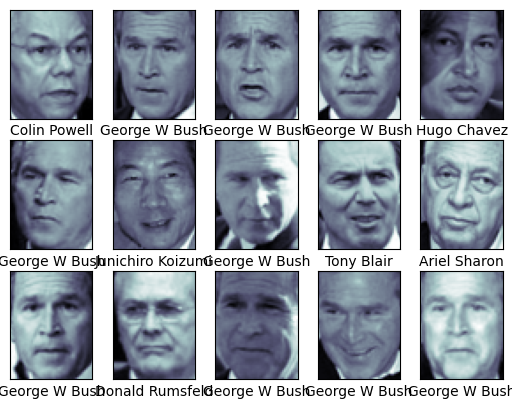

In [ ]:

# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])


Langkah 2 — Pra-Pengolahan Data dengan PCA

In [ ]:

from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)


Langkah 3 — Split Data

In [ ]:

# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)


Langkah 4 — Pembuatan Model dan Tuning Hyperparameter

Menentukan parameter yang diuji

In [ ]:

from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)


CPU times: user 2min 22s, sys: 226 ms, total: 2min 22s
Wall time: 1min 56s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Menggunakan model terbaik untuk prediksi

In [ ]:

model = grid.best_estimator_
yfit = model.predict(Xtest)


Langkah 5 — Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

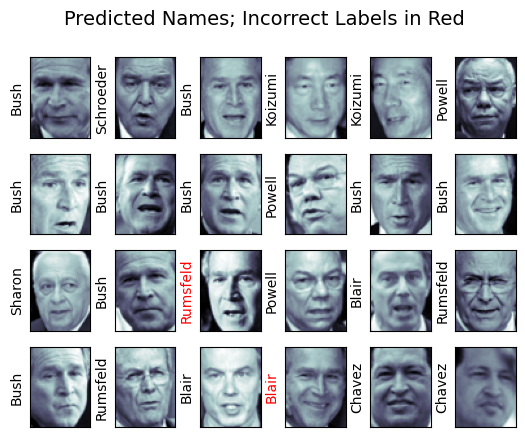

In [ ]:

# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)


Langkah 6 — Cek Performansi Model

Menampilkan classification report

In [ ]:

from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))


                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Membuat confusion matrix

Text(113.92222222222219, 0.5, 'predicted label')

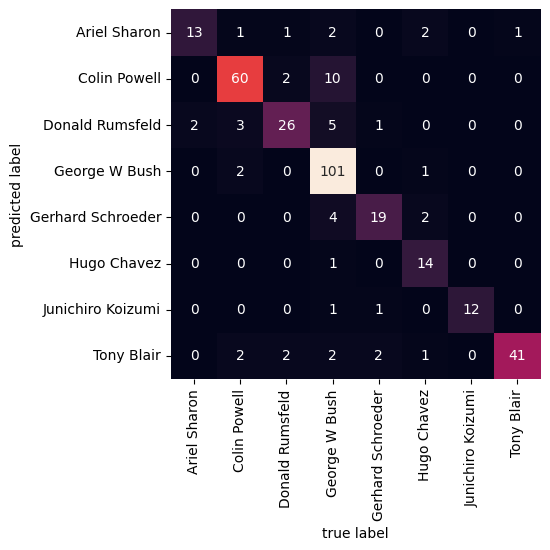

In [ ]:

# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')


## **Praktikum 5**

Langkah 0 — Import Library

In [ ]:

# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd


In [ ]:

# Image directories
train_dir = "images/training/"
test_dir = "images/test/"


In [ ]:

# Mengambil dataset dari File Explorer
from google.colab import files
import zipfile
from pathlib import Path

# Memilih file dataset dari komputer
uploaded = files.upload()

# Mengekstrak file ZIP
extract_dir = Path("/content/dataset_praktikum5")
extract_dir.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall(extract_dir)
        print("Dataset berhasil diekstrak:", filename)
    else:
        print("File bukan ZIP:", filename)

# Mencari folder images yang berisi training dan test
images_dirs = [
    folder for folder in extract_dir.rglob("images")
    if (folder / "training").is_dir()
    and (folder / "test").is_dir()
]

if images_dirs:
    images_dir = images_dirs[0]
    train_dir = str(images_dir / "training")
    test_dir = str(images_dir / "test")

    print("Folder training:", train_dir)
    print("Folder test:", test_dir)
else:
    print("Folder images/training dan images/test belum ditemukan.")
    print("Periksa struktur folder hasil ekstraksi:")
    for folder in extract_dir.iterdir():
        print(folder)


Saving images.zip to images.zip
Dataset berhasil diekstrak: images.zip
Folder training: /content/dataset_praktikum5/images/training
Folder test: /content/dataset_praktikum5/images/test


Langkah 1 — Load Data dan Visualisasikan

Membuat fungsi untuk memuat dataset

In [ ]:

def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list


Memuat data training

In [ ]:

# Load training data
train_img = load_dataset(train_dir)


Memeriksa data pertama

In [ ]:

# Check the first data
# It should be a tuple consist of arrays of image and image labels
train_img[0]


(array([[[ 95, 124, 142],
         [ 94, 123, 141],
         [ 92, 121, 139],
         ...,
         [ 86, 103, 119],
         [ 83,  96, 113],
         [119, 132, 149]],
 
        [[ 94, 123, 141],
         [ 94, 123, 141],
         [ 92, 121, 139],
         ...,
         [ 86, 103, 119],
         [ 83,  96, 113],
         [119, 132, 149]],
 
        [[ 94, 123, 141],
         [ 93, 122, 140],
         [ 93, 122, 140],
         ...,
         [ 86, 103, 119],
         [ 83,  96, 113],
         [119, 132, 149]],
 
        ...,
 
        [[157, 141, 105],
         [157, 141, 105],
         [156, 140, 104],
         ...,
         [ 64,  68,  43],
         [ 62,  68,  42],
         [ 59,  65,  39]],
 
        [[159, 143, 107],
         [158, 142, 106],
         [157, 141, 105],
         ...,
         [ 61,  65,  40],
         [ 58,  64,  38],
         [ 54,  60,  34]],
 
        [[191, 176, 137],
         [190, 175, 136],
         [189, 174, 135],
         ...,
         [ 63,  67,  42],
  

Memeriksa ukuran gambar secara acak

In [ ]:

# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)


Image 93
(700, 1280, 3)


Membuat fungsi visualisasi

In [ ]:

# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'
    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')


Menampilkan gambar acak

Shape	: (372, 640, 3)
Label	: night


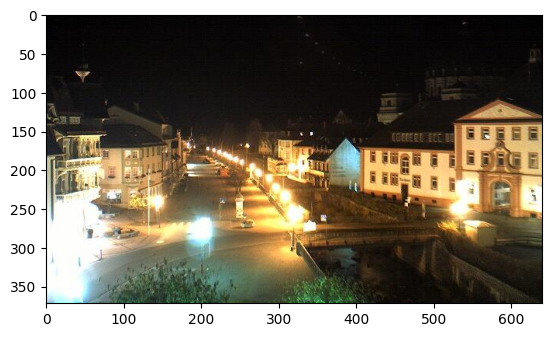

In [ ]:

random_img_viz(train_img)


Langkah 3 — Pra Pengolahan Data

3.1 — Standardisasi ukuran gambar

In [ ]:

def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img


3.2 — Encoding label gambar

In [ ]:

def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val


3.3 — Membuat fungsi preprocessing

In [ ]:

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list


3.4 — Melakukan preprocessing pada data training

In [ ]:

train_std_img_list = preprocess(train_img)


3.5 — Memeriksa ukuran gambar hasil preprocessing

In [ ]:

# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))
# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)


Image 35
(600, 1100, 3)


3.6 — Inspeksi visual hasil preprocessing

Shape	: (600, 1100, 3)
Label	: 0


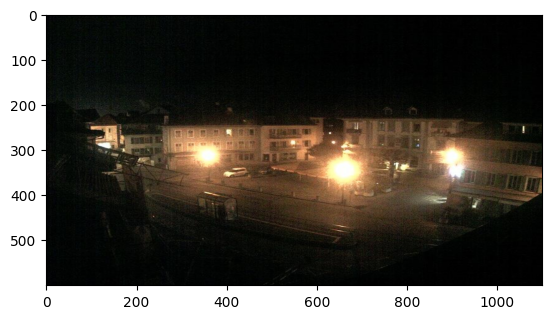

In [ ]:

random_img_viz(train_std_img_list)


## **Tugas Praktikum**

Tugas 1 — Model SVM menggunakan voice.csv

Langkah 1.1 — Mengambil dataset voice.csv

In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()


Saving voice (1).csv to voice (1) (1).csv


In [ ]:

df = pd.read_csv('voice (1).csv')

print("Ukuran dataset:", df.shape)
display(df.head())
print("Nama kolom:", df.columns.tolist())


Ukuran dataset: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Nama kolom: ['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']


1.2 — Menyiapkan fitur dan label

In [ ]:

# Memisahkan fitur dan label
X = df.drop(columns=['label'])
y = df['label']

print("Jumlah data:", len(df))
print("Jumlah fitur:", X.shape[1])
print("Kelas label:")
print(y.value_counts())


Jumlah data: 3168
Jumlah fitur: 20
Kelas label:
label
male      1584
female    1584
Name: count, dtype: int64


1.3 — Mengimpor library SVM dan evaluasi

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd


1.4 — Membuat enam model SVM

In [ ]:

hasil = []

rasio_split = [
    (0.30, "70:30"),
    (0.20, "80:20")
]

kernel_svm = [
    ("Linear", "linear"),
    ("Polynomial", "poly"),
    ("RBF", "rbf")
]

for test_size, rasio in rasio_split:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    for nama_kernel, kernel in kernel_svm:
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel=kernel)
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        akurasi = accuracy_score(y_test, y_pred)

        hasil.append({
            "Rasio Split": rasio,
            "Kernel": nama_kernel,
            "Akurasi": akurasi
        })

df_hasil = pd.DataFrame(hasil)
display(df_hasil)


,Rasio Split,Kernel,Akurasi
0,70:30,Linear,0.978970
1,70:30,Polynomial,0.960042
2,70:30,RBF,0.983176
3,80:20,Linear,0.974763
4,80:20,Polynomial,0.955836
5,80:20,RBF,0.982650


1.5 — Membaca tabel akurasi

In [ ]:

# Menampilkan tabel hasil akurasi dalam persentase
df_hasil_tampil = df_hasil.copy()
df_hasil_tampil["Akurasi (%)"] = df_hasil_tampil["Akurasi"] * 100

display(df_hasil_tampil.round(2))


,Rasio Split,Kernel,Akurasi,Akurasi (%)
0,70:30,Linear,0.98,97.90
1,70:30,Polynomial,0.96,96.00
2,70:30,RBF,0.98,98.32
3,80:20,Linear,0.97,97.48
4,80:20,Polynomial,0.96,95.58
5,80:20,RBF,0.98,98.26


1.6 - Grafik perbandingan akurasi

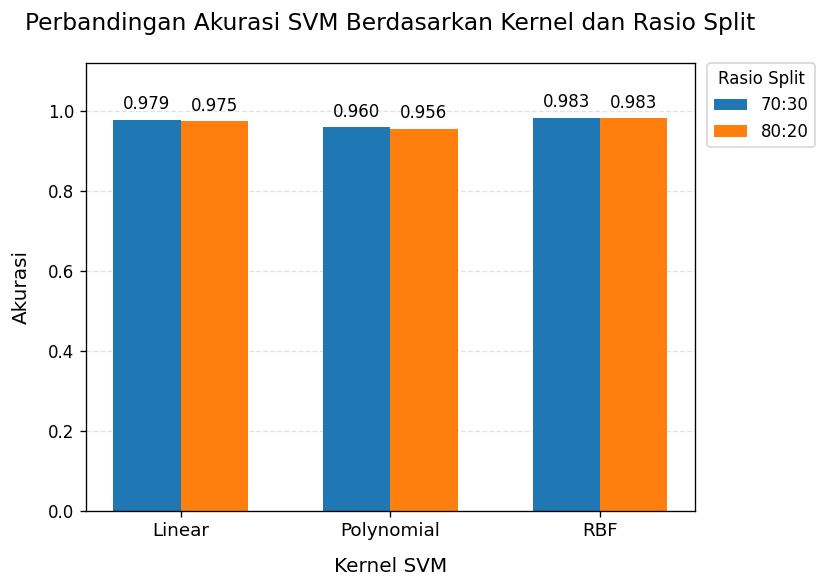

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Menyiapkan data hasil akurasi
pivot_hasil = df_hasil.pivot(
    index="Kernel",
    columns="Rasio Split",
    values="Akurasi"
)

# Mengatur urutan kernel dan rasio split
pivot_hasil = pivot_hasil.reindex(
    index=["Linear", "Polynomial", "RBF"],
    columns=["70:30", "80:20"]
)

# Membuat grafik dengan ukuran lebih besar
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)

# Posisi batang dan lebar batang
x = np.arange(len(pivot_hasil.index))
width = 0.32

bars1 = ax.bar(
    x - width / 2,
    pivot_hasil["70:30"],
    width,
    label="70:30"
)

bars2 = ax.bar(
    x + width / 2,
    pivot_hasil["80:20"],
    width,
    label="80:20"
)

# Judul dan label sumbu
ax.set_title(
    "Perbandingan Akurasi SVM Berdasarkan Kernel dan Rasio Split",
    fontsize=14,
    pad=20
)
ax.set_xlabel("Kernel SVM", fontsize=12, labelpad=10)
ax.set_ylabel("Akurasi", fontsize=12, labelpad=10)

# Label kategori dan rentang sumbu Y
ax.set_xticks(x)
ax.set_xticklabels(pivot_hasil.index, fontsize=11)
ax.set_ylim(0, 1.12)

# Memindahkan legenda ke posisi yang tidak menutupi batang
ax.legend(
    title="Rasio Split",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10
)

# Menampilkan nilai akurasi dengan jarak yang cukup
ax.bar_label(
    bars1,
    labels=[f"{v:.3f}" for v in pivot_hasil["70:30"]],
    padding=4,
    fontsize=10
)

ax.bar_label(
    bars2,
    labels=[f"{v:.3f}" for v in pivot_hasil["80:20"]],
    padding=4,
    fontsize=10
)

# Memperjelas grid dan tata letak
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()


Tugas 2 — Klasifikasi siang dan malam menggunakan SVM RBF dengan fitur histogram

Langkah 2.1 — Mengekstrak fitur histogram

In [ ]:

import numpy as np
import cv2
import pandas as pd

def extract_histogram(image):
    # Mengubah gambar ke format uint8
    if image.dtype != np.uint8:
        if image.max() <= 1:
            image = (image * 255).astype(np.uint8)
        else:
            image = image.astype(np.uint8)

    # Histogram untuk setiap kanal RGB
    hist_features = []

    for channel in range(3):
        hist = cv2.calcHist(
            [image],
            [channel],
            None,
            [32],
            [0, 256]
        )

        # Normalisasi histogram
        hist = cv2.normalize(hist, hist).flatten()
        hist_features.extend(hist)

    return hist_features


Langkah 2.2 — Membentuk dataset fitur dan label

In [ ]:

X_hist = []
y_hist = []

for image, label in train_std_img_list:
    features = extract_histogram(image)
    X_hist.append(features)
    y_hist.append(label)

X_hist = np.array(X_hist)
y_hist = np.array(y_hist)

print("Ukuran fitur histogram:", X_hist.shape)
print("Ukuran label:", y_hist.shape)
print("Jumlah kelas:")
print(pd.Series(y_hist).value_counts())


Ukuran fitur histogram: (240, 96)
Ukuran label: (240,)
Jumlah kelas:
1    120
0    120
Name: count, dtype: int64


Langkah 2.3 — Membagi data dengan rasio 80:20

In [ ]:

from sklearn.model_selection import train_test_split

X_train_hist, X_test_hist, y_train_hist, y_test_hist = train_test_split(
    X_hist,
    y_hist,
    test_size=0.20,
    random_state=42,
    stratify=y_hist
)

print("Jumlah data training:", len(X_train_hist))
print("Jumlah data testing:", len(X_test_hist))


Jumlah data training: 192
Jumlah data testing: 48


Langkah 2.4 — Membuat model SVM dengan kernel RBF

In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model_rbf = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

model_rbf.fit(X_train_hist, y_train_hist)

y_pred_hist = model_rbf.predict(X_test_hist)

akurasi_awal = accuracy_score(y_test_hist, y_pred_hist)

print(f"Akurasi awal SVM RBF: {akurasi_awal:.4f}")
print(f"Akurasi awal (%): {akurasi_awal * 100:.2f}%")


Akurasi awal SVM RBF: 1.0000
Akurasi awal (%): 100.00%


Langkah 2.5 — Melakukan hyperparameter tuning

In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline_rbf = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline_rbf,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train_hist, y_train_hist)

print("Parameter terbaik:", grid_search.best_params_)
print(f"Akurasi validasi terbaik: {grid_search.best_score_:.4f}")


Parameter terbaik: {'svc__C': 1, 'svc__gamma': 'scale'}
Akurasi validasi terbaik: 0.9947


Langkah 2.6 — Mengevaluasi model terbaik pada data testing

In [ ]:

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test_hist)

akurasi_tuned = accuracy_score(y_test_hist, y_pred_tuned)

print(f"Akurasi SVM RBF setelah tuning: {akurasi_tuned:.4f}")
print(f"Akurasi SVM RBF setelah tuning (%): {akurasi_tuned * 100:.2f}%")


Akurasi SVM RBF setelah tuning: 1.0000
Akurasi SVM RBF setelah tuning (%): 100.00%


Langkah 2.7 — Membandingkan hasil

In [ ]:

df_perbandingan = pd.DataFrame([
    {
        "Model": "SVM RBF - Parameter Awal",
        "Akurasi": akurasi_awal,
        "Akurasi (%)": akurasi_awal * 100
    },
    {
        "Model": "SVM RBF - Setelah Tuning",
        "Akurasi": akurasi_tuned,
        "Akurasi (%)": akurasi_tuned * 100
    }
])

display(df_perbandingan.round(4))


,Model,Akurasi,Akurasi (%)
0,SVM RBF - Parameter Awal,1.0,100.0
1,SVM RBF - Setelah Tuning,1.0,100.0


2.8 - Akurasi SVM RBF Sebelum dan Sesudah Tuning

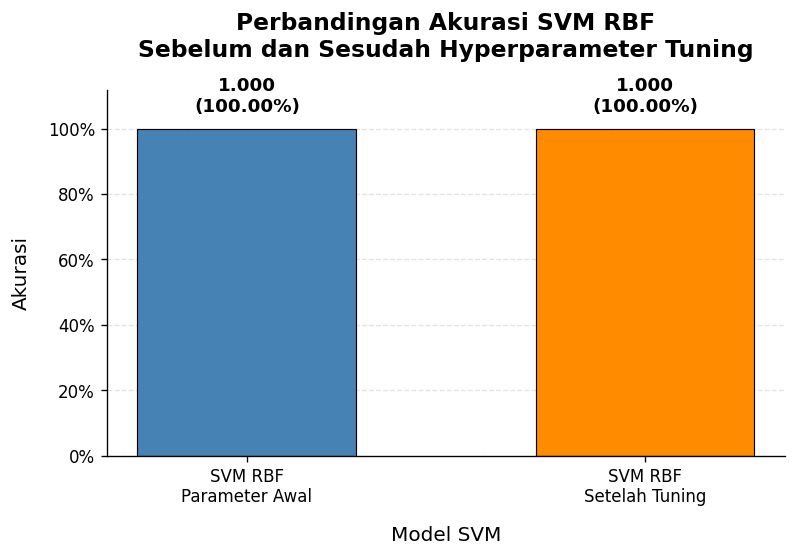

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Menyiapkan data akurasi
nama_model = [
    "SVM RBF\nParameter Awal",
    "SVM RBF\nSetelah Tuning"
]

nilai_akurasi = [
    akurasi_awal,
    akurasi_tuned
]

# Membuat grafik dengan ukuran dan resolusi lebih besar
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)

# Posisi batang
x = np.arange(len(nama_model))

# Membuat grafik batang
bars = ax.bar(
    x,
    nilai_akurasi,
    width=0.55,
    color=["steelblue", "darkorange"],
    edgecolor="black",
    linewidth=0.7
)

# Judul dan label sumbu
ax.set_title(
    "Perbandingan Akurasi SVM RBF\nSebelum dan Sesudah Hyperparameter Tuning",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Model SVM", fontsize=12, labelpad=12)
ax.set_ylabel("Akurasi", fontsize=12, labelpad=10)

# Mengatur label sumbu X
ax.set_xticks(x)
ax.set_xticklabels(nama_model, fontsize=10)

# Memberi ruang di atas batang untuk label nilai
nilai_maksimum = max(nilai_akurasi)
ax.set_ylim(0, max(1.10, nilai_maksimum + 0.12))

# Format sumbu Y menjadi persentase
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

# Menampilkan nilai akurasi dan persentase di atas batang
for bar, nilai in zip(bars, nilai_akurasi):
    ax.annotate(
        f"{nilai:.3f}\n({nilai * 100:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Memperjelas grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)
ax.set_axisbelow(True)

# Mengurangi garis tepi yang tidak diperlukan
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Mengatur jarak elemen grafik
fig.tight_layout(pad=2)

plt.show()


,C,gamma,Rata-rata Akurasi Validasi,Standar Deviasi
0,0.1,scale,0.9479,0.0324
1,0.1,0.01,0.9321,0.0389
2,0.1,0.1,0.8704,0.0806
3,0.1,1,0.5789,0.0671
4,1.0,scale,0.9947,0.0105
5,1.0,0.01,0.9947,0.0105
6,1.0,0.1,0.9895,0.0211
7,1.0,1,0.8335,0.0106
8,10.0,scale,0.9947,0.0105
9,10.0,0.01,0.9947,0.0105


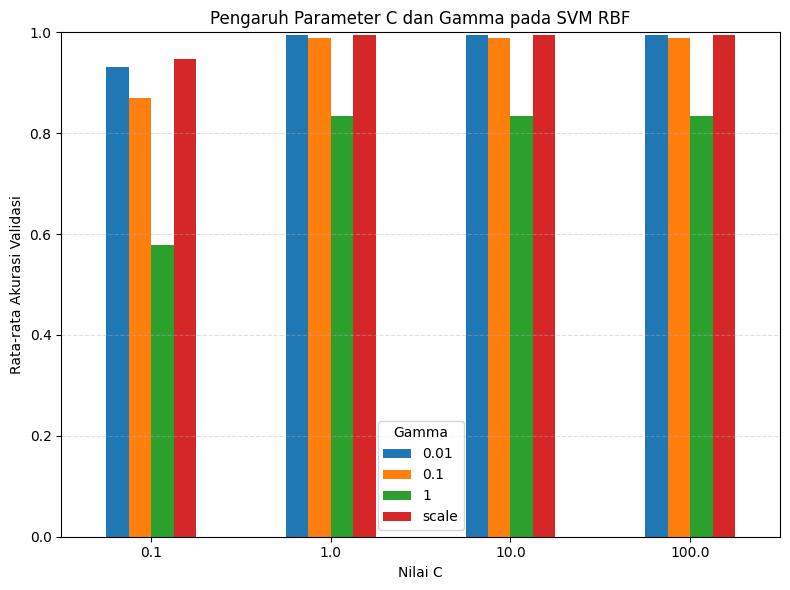

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Mengambil hasil validasi silang
df_tuning = pd.DataFrame(grid_search.cv_results_)

# Mengambil nilai parameter dan akurasi validasi
df_tuning["C"] = df_tuning["param_svc__C"].astype(float)
df_tuning["gamma"] = df_tuning["param_svc__gamma"].astype(str)

# Membuat tabel ringkasan
tabel_tuning = df_tuning[
    ["C", "gamma", "mean_test_score", "std_test_score"]
].rename(columns={
    "mean_test_score": "Rata-rata Akurasi Validasi",
    "std_test_score": "Standar Deviasi"
})

display(tabel_tuning.round(4))

# Visualisasi hasil tuning
pivot_tuning = tabel_tuning.pivot(
    index="C",
    columns="gamma",
    values="Rata-rata Akurasi Validasi"
)

pivot_tuning.plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Pengaruh Parameter C dan Gamma pada SVM RBF")
plt.xlabel("Nilai C")
plt.ylabel("Rata-rata Akurasi Validasi")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Gamma")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
